In [1]:
import sys, os, tempfile
sys.path.append("..")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
from sklearn.model_selection import GridSearchCV, cross_val_score, cross_val_predict
from sklearn.inspection import permutation_importance
from sklearn.preprocessing import label_binarize
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             confusion_matrix, ConfusionMatrixDisplay, classification_report, roc_curve)

from src.data import load_data, get_column_types, RISK_ORDER
from src.preprocessing import prepare_data, RANDOM_STATE
from src.models import train_models
from src.tuning import tune_models, CV, SCORING, LOGREG_GRID, SVC_PARAMS

In [2]:
X_train, X_test, y_train, y_test = prepare_data(load_data())
base, _ = train_models(X_train, X_test, y_train, y_test)

print("Train:", X_train.shape, "| Test:", X_test.shape)
print("CV:", CV.n_splits, "folds, stratified | scoring:", SCORING)

Train: (1570, 15) | Test: (393, 15)
CV: 5 folds, stratified | scoring: f1_macro


In [3]:
rows = {}
for name, pipe in base.items():
    cv_f1 = cross_val_score(pipe, X_train, y_train, cv=CV, scoring=SCORING, n_jobs=-1).mean()
    train_f1 = f1_score(y_train, pipe.predict(X_train), average="macro")
    rows[name] = {"cv_f1": cv_f1, "train_f1": train_f1, "gap": train_f1 - cv_f1}
baseline = pd.DataFrame(rows).T
baseline.round(3)

,cv_f1,train_f1,gap
LogisticRegression,0.742,0.759,0.017
RandomForest,0.666,1.000,0.334
SVC,0.721,0.833,0.113


In [4]:
SELECTED = ["LogisticRegression", "SVC"]

In [5]:
print(LOGREG_GRID)
grid = GridSearchCV(base["LogisticRegression"], LOGREG_GRID, scoring=SCORING, cv=CV,
                    n_jobs=-1, return_train_score=True).fit(X_train, y_train)

print("Best params:", grid.best_params_)
print("Best CV F1:", round(grid.best_score_, 3))

{'model__C': [0.01, 0.03, 0.1, 0.3, 1, 3, 10, 30, 100]}
Best params: {'model__C': 30}
Best CV F1: 0.744


In [6]:
print(SVC_PARAMS)
svc_search = GridSearchCV(base["SVC"], SVC_PARAMS, scoring=SCORING, cv=CV,
                          n_jobs=-1, return_train_score=True).fit(X_train, y_train)

print("Best params:", svc_search.best_params_)
print("Best CV F1:", round(svc_search.best_score_, 3))

{'model__estimator__C': [1, 3, 10, 30, 100, 300], 'model__estimator__gamma': [0.0001, 0.0003, 0.001, 0.003, 0.01, 'scale']}
Best params: {'model__estimator__C': 100, 'model__estimator__gamma': 0.003}
Best CV F1: 0.737


In [7]:
tuned = {"LogisticRegression": grid, "SVC": svc_search}

comp = pd.DataFrame({
    name: {
        "cv_f1_default": baseline.loc[name, "cv_f1"],
        "cv_f1_tuned": s.best_score_,
        "cv_std_tuned": s.cv_results_["std_test_score"][s.best_index_],
        "train_f1_tuned": f1_score(y_train, s.best_estimator_.predict(X_train), average="macro"),
    } for name, s in tuned.items()
}).T
comp["gap_tuned"] = comp["train_f1_tuned"] - comp["cv_f1_tuned"]
comp.round(3)

,cv_f1_default,cv_f1_tuned,cv_std_tuned,train_f1_tuned,gap_tuned
LogisticRegression,0.742,0.744,0.018,0.759,0.016
SVC,0.721,0.737,0.022,0.773,0.036


In [8]:
oof = {n: cross_val_predict(s.best_estimator_, X_train, y_train, cv=CV, n_jobs=-1) for n, s in tuned.items()}
HIGH, MEDIUM = RISK_ORDER.index("High"), RISK_ORDER.index("Medium")

pd.DataFrame({
    n: {"oof_f1": f1_score(y_train, p, average="macro"),
        "oof_recall_High": recall_score(y_train, p, labels=[HIGH], average=None)[0],
        "oof_recall_Medium": recall_score(y_train, p, labels=[MEDIUM], average=None)[0]}
    for n, p in oof.items()
}).T.round(3)

,oof_f1,oof_recall_High,oof_recall_Medium
LogisticRegression,0.744,0.815,0.620
SVC,0.738,0.840,0.572


In [9]:
best_name = max(tuned, key=lambda n: tuned[n].best_score_)
best_pipeline = tuned[best_name].best_estimator_
print("Chosen (highest CV F1):", best_name)

Chosen (highest CV F1): LogisticRegression


In [10]:
pred = best_pipeline.predict(X_test)
proba = best_pipeline.predict_proba(X_test)

print({
    "accuracy": round(accuracy_score(y_test, pred), 3),
    "precision": round(precision_score(y_test, pred, average="macro"), 3),
    "recall": round(recall_score(y_test, pred, average="macro"), 3),
    "f1": round(f1_score(y_test, pred, average="macro"), 3),
    "roc_auc": round(roc_auc_score(y_test, proba, multi_class="ovr", average="macro"), 3),
})
print(classification_report(y_test, pred, target_names=RISK_ORDER, digits=3))

{'accuracy': 0.786, 'precision': 0.787, 'recall': 0.786, 'f1': 0.786, 'roc_auc': 0.923}
              precision    recall  f1-score   support

         Low      0.830     0.862     0.845       130
      Medium      0.672     0.682     0.677       129
        High      0.858     0.813     0.835       134

    accuracy                          0.786       393
   macro avg      0.787     0.786     0.786       393
weighted avg      0.788     0.786     0.787       393



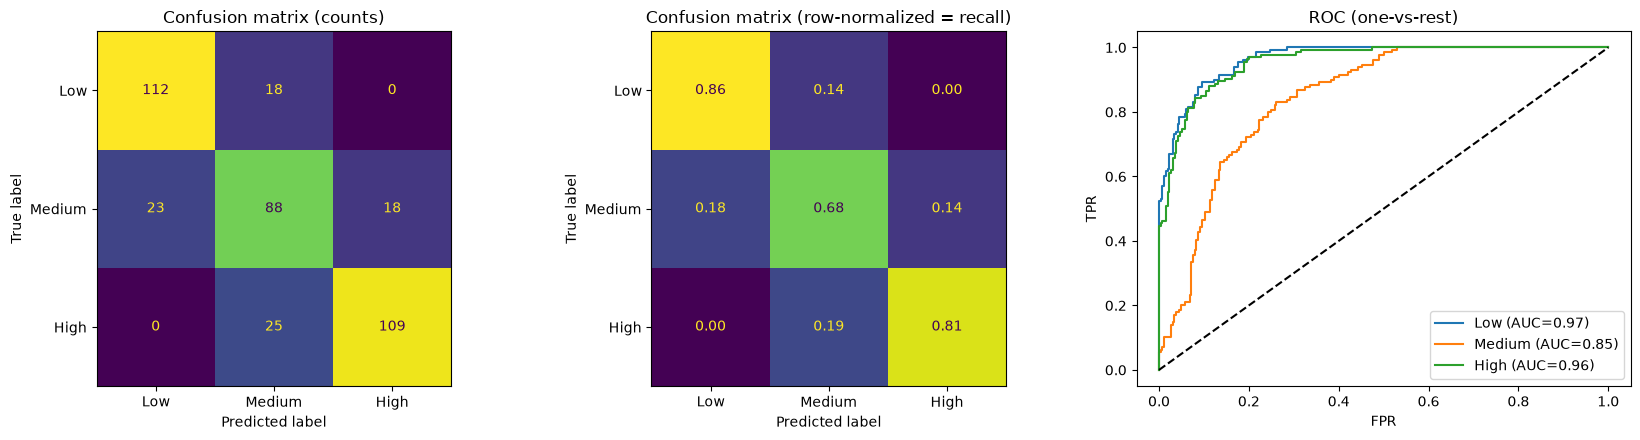

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))

ConfusionMatrixDisplay(confusion_matrix(y_test, pred), display_labels=RISK_ORDER).plot(ax=axes[0], colorbar=False)
axes[0].set_title("Confusion matrix (counts)")

ConfusionMatrixDisplay(confusion_matrix(y_test, pred, normalize="true"), display_labels=RISK_ORDER).plot(
    ax=axes[1], colorbar=False, values_format=".2f")
axes[1].set_title("Confusion matrix (row-normalized = recall)")

y_bin = label_binarize(y_test, classes=[0, 1, 2])
for i, risk in enumerate(RISK_ORDER):
    fpr, tpr, _ = roc_curve(y_bin[:, i], proba[:, i])
    axes[2].plot(fpr, tpr, label=f"{risk} (AUC={roc_auc_score(y_bin[:, i], proba[:, i]):.2f})")
axes[2].plot([0, 1], [0, 1], "k--")
axes[2].set_title("ROC (one-vs-rest)")
axes[2].set_xlabel("FPR")
axes[2].set_ylabel("TPR")
axes[2].legend()
plt.tight_layout()
plt.show()

In [12]:
labels = dict(enumerate(RISK_ORDER))
errors = X_test.assign(
    true=y_test.map(labels),
    pred=pd.Series(pred, index=y_test.index).map(labels),
    confidence=proba.max(axis=1),
)
errors["wrong"] = errors["true"] != errors["pred"]

print("Errors:", errors["wrong"].sum(), "/", len(errors))
print("\nError rate per true class:\n", errors.groupby("true")["wrong"].mean().reindex(RISK_ORDER).round(3))

dist = np.abs(y_test.values - pred)
print("\nAdjacent errors (Low<->Medium, Medium<->High):", (dist == 1).sum())
print("Extreme errors (Low<->High):", (dist == 2).sum())

print("\nMean confidence of the predicted class:\n", errors.groupby("wrong")["confidence"].mean().round(3))

Errors: 84 / 393

Error rate per true class:
 true
Low       0.138
Medium    0.318
High      0.187
Name: wrong, dtype: float64

Adjacent errors (Low<->Medium, Medium<->High): 84
Extreme errors (Low<->High): 0

Mean confidence of the predicted class:
 wrong
False    0.797
True     0.661
Name: confidence, dtype: float64


In [13]:
numeric_cols, _ = get_column_types(X_test)
errors.groupby("wrong")[numeric_cols].mean().T.round(2)

wrong,False,True
Age,21.06,21.00
Year_of_Study,2.63,2.64
Sleep_Hours,6.76,6.67
Study_Hours_Per_Week,19.87,19.95
GPA,2.56,2.52
Social_Media_Hours,6.03,6.00
Screen_Time_Hours,8.54,8.62
Financial_Stress,5.84,5.82
Family_Support,6.74,6.26
Attendance_Rate,84.86,85.07


In [14]:
imp = permutation_importance(best_pipeline, X_test, y_test, scoring=SCORING, n_repeats=10,
                             random_state=RANDOM_STATE, n_jobs=-1)
pd.Series(imp.importances_mean, index=X_test.columns).sort_values(ascending=False).round(3)

Sleep_Hours                       0.268
Financial_Stress                  0.140
Family_Support                    0.117
Previous_Mental_Health_History    0.108
Physical_Activity                 0.099
GPA                               0.060
Diet_Quality                      0.028
Part_Time_Job                     0.018
Study_Hours_Per_Week              0.018
Social_Media_Hours                0.018
Attendance_Rate                   0.006
Screen_Time_Hours                 0.005
Year_of_Study                     0.003
Age                               0.001
Gender                           -0.005
dtype: float64

In [15]:
os.makedirs("../models", exist_ok=True)
joblib.dump(best_pipeline, "../models/best_pipeline.joblib")

loaded = joblib.load("../models/best_pipeline.joblib")
assert (loaded.predict(X_test) == pred).all()
print("Reloaded pipeline gives identical predictions")
loaded.predict(X_test.iloc[[0]])   

Reloaded pipeline gives identical predictions


array([2])